<a href="https://colab.research.google.com/github/Advanced-Forecasting-Project/NYC-Car-Crashes-Forecasting/blob/afomia/Forecasting_Project_Cleaning_Afomia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NYC Motor Vehicle Collisions: Data Cleaning

This notebook checks the NYPD crash records and builds the crash-count series used for forecasting (daily, plus weekly and monthly versions).

**Cleaning rules used throughout**
- A row is removed only if there is a clear reason (invalid date, confirmed duplicate). Each removal is counted and explained.
- Missing values in columns we don't use for the target are reported, not filled.
- Every output is followed by a short note on what it means for the forecast.

The data is loaded straight from our group's GitHub release, so the notebook runs from top to bottom without uploading any files.

## Setup

All imports and file names are defined once here, so later cells don't repeat them.

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Source data and output file names
DATA_URL = (
    "https://github.com/Advanced-Forecasting-Project/NYC-Car-Crashes-Forecasting/"
    "releases/download/data-v1/Motor_Vehicle_Collisions_-_Crashes.zip"
)

# Display settings
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (12, 4)

# Load the raw crash records
crashes = pd.read_csv(DATA_URL, compression="zip", low_memory=False)

print("Rows:", f"{len(crashes):,}")
print("Columns:", crashes.shape[1])
crashes.head()

Rows: 2,018,963
Columns: 29


,CRASH DATE,CRASH TIME,BOROUGH,ZIP CODE,LATITUDE,LONGITUDE,LOCATION,ON STREET NAME,CROSS STREET NAME,OFF STREET NAME,NUMBER OF PERSONS INJURED,NUMBER OF PERSONS KILLED,NUMBER OF PEDESTRIANS INJURED,NUMBER OF PEDESTRIANS KILLED,NUMBER OF CYCLIST INJURED,NUMBER OF CYCLIST KILLED,NUMBER OF MOTORIST INJURED,NUMBER OF MOTORIST KILLED,CONTRIBUTING FACTOR VEHICLE 1,CONTRIBUTING FACTOR VEHICLE 2,CONTRIBUTING FACTOR VEHICLE 3,CONTRIBUTING FACTOR VEHICLE 4,CONTRIBUTING FACTOR VEHICLE 5,COLLISION_ID,VEHICLE TYPE CODE 1,VEHICLE TYPE CODE 2,VEHICLE TYPE CODE 3,VEHICLE TYPE CODE 4,VEHICLE TYPE CODE 5
0,09/11/2021,2:39,NaN,NaN,NaN,NaN,NaN,WHITESTONE EXPRESSWAY,20 AVENUE,NaN,2.0,0.0,0,0,0,0,2,0,Aggressive Driving/Road Rage,Unspecified,NaN,NaN,NaN,4455765,Sedan,Sedan,NaN,NaN,NaN
1,03/26/2022,11:45,NaN,NaN,NaN,NaN,NaN,QUEENSBORO BRIDGE UPPER,NaN,NaN,1.0,0.0,0,0,0,0,1,0,Pavement Slippery,NaN,NaN,NaN,NaN,4513547,Sedan,NaN,NaN,NaN,NaN
2,06/29/2022,6:55,NaN,NaN,NaN,NaN,NaN,THROGS NECK BRIDGE,NaN,NaN,0.0,0.0,0,0,0,0,0,0,Following Too Closely,Unspecified,NaN,NaN,NaN,4541903,Sedan,Pick-up Truck,NaN,NaN,NaN
3,09/11/2021,9:35,BROOKLYN,11208,40.667202,-73.866500,"(40.667202, -73.8665)",NaN,NaN,1211 LORING AVENUE,0.0,0.0,0,0,0,0,0,0,Unspecified,NaN,NaN,NaN,NaN,4456314,Sedan,NaN,NaN,NaN,NaN
4,12/14/2021,8:13,BROOKLYN,11233,40.683304,-73.917274,"(40.683304, -73.917274)",SARATOGA AVENUE,DECATUR STREET,NaN,0.0,0.0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,4486609,NaN,NaN,NaN,NaN,NaN


## Data Types

Check the data types of each column. A column that should be a date or a number but was read as text will be converted

In [24]:
# For each column: its data type and the first non-missing value as an example
column_overview = pd.DataFrame({
    "data_type": crashes.dtypes.astype(str),
    "example_value": crashes.apply(lambda col: col.loc[col.first_valid_index()]),
})

column_overview

,data_type,example_value
CRASH DATE,object,09/11/2021
CRASH TIME,object,2:39
BOROUGH,object,BROOKLYN
ZIP CODE,object,11208
LATITUDE,float64,40.667202
LONGITUDE,float64,-73.8665
LOCATION,object,"(40.667202, -73.8665)"
ON STREET NAME,object,WHITESTONE EXPRESSWAY
CROSS STREET NAME,object,20 AVENUE
OFF STREET NAME,object,1211 LORING AVENUE


- **CRASH DATE is stored as text**, not as a date.
- **NUMBER OF PERSONS INJURED and NUMBER OF PERSONS KILLED are stored as decimals (float64)**, while the pedestrian, cyclist and motorist counts are whole numbers (int64). The example values (2.0, 0.0) show they are still whole numbers.
- **CRASH TIME and ZIP CODE are stored as text.** We don't use either for the city-wide daily count, so they don't need converting.
- The remaining columns (location, contributing factors, vehicle types) are descriptive text and were read as expected.

In [25]:
# Convert CRASH DATE from text to a real date.
# Any value that doesn't match month/day/year becomes NaT (missing date) instead of causing an error.
crashes["CRASH DATE"] = pd.to_datetime(crashes["CRASH DATE"], format="%m/%d/%Y", errors="coerce")

print("Invalid or missing dates:", crashes["CRASH DATE"].isna().sum())
print("First date:", crashes["CRASH DATE"].min().date())
print("Last date: ", crashes["CRASH DATE"].max().date())

Invalid or missing dates: 0
First date: 2012-07-01
Last date:  2023-08-18


All crash dates are valid, so no rows need removing for this reason. The data covers **1 July 2012 to 18 August 2023**, just over 11 years of daily records. The data starts on the first day of a month but ends mid-month

In [26]:
#Check Collision IDs and exact duplicates
print("Missing collision IDs:", crashes["COLLISION_ID"].isna().sum())
print("Repeated collision IDs:", crashes["COLLISION_ID"].duplicated().sum())
print("Fully identical rows:", crashes.duplicated().sum())

Missing collision IDs: 0
Repeated collision IDs: 0
Fully identical rows: 0


### Hidden duplicates (same crash, different ID)

Here we compare rows on every column except COLLISION_ID. Two rows that match on date, time to the minute, location, injury counts, contributing factors and vehicle types are very likely the same crash reported twice.

In [27]:
# All columns except the ID
cols_without_id = crashes.columns.drop("COLLISION_ID")

# keep="first": marks only the extra copies (the rows we would remove)
# keep=False:   marks every row in a matching group, including the first one
extra_copies = crashes.duplicated(subset=cols_without_id, keep="first")
in_matching_group = crashes.duplicated(subset=cols_without_id, keep=False)

print("Extra copies:", extra_copies.sum())
print("Rows in a matching group (originals + copies):", in_matching_group.sum())

# How many of the matching rows have no location at all?
matched = crashes[in_matching_group]
print(f"Matching rows with no coordinates: {matched['LATITUDE'].isna().mean():.0%}")

# Show some examples, sorted so matching rows sit next to each other
show_cols = ["CRASH DATE", "CRASH TIME", "BOROUGH", "ON STREET NAME",
             "NUMBER OF PERSONS INJURED", "CONTRIBUTING FACTOR VEHICLE 1",
             "VEHICLE TYPE CODE 1", "COLLISION_ID"]
matched.sort_values(["CRASH DATE", "CRASH TIME", "COLLISION_ID"])[show_cols].head(10)

Extra copies: 1710
Rows in a matching group (originals + copies): 3348
Matching rows with no coordinates: 19%


,CRASH DATE,CRASH TIME,BOROUGH,ON STREET NAME,NUMBER OF PERSONS INJURED,CONTRIBUTING FACTOR VEHICLE 1,VEHICLE TYPE CODE 1,COLLISION_ID
1924813,2012-07-02,19:40,QUEENS,QUEENS BOULEVARD,0.0,Unspecified,LIVERY VEHICLE,255006
1921054,2012-07-02,19:40,QUEENS,QUEENS BOULEVARD,0.0,Unspecified,LIVERY VEHICLE,255007
1922776,2012-07-04,1:04,NaN,NaN,1.0,Unspecified,MOTORCYCLE,2872821
1923842,2012-07-04,1:04,NaN,NaN,1.0,Unspecified,MOTORCYCLE,2872822
1924145,2012-07-06,18:20,NaN,NaN,0.0,Driver Inattention/Distraction,PASSENGER VEHICLE,2949954
1920859,2012-07-06,18:20,NaN,NaN,0.0,Driver Inattention/Distraction,PASSENGER VEHICLE,2949955
1924292,2012-07-07,21:00,MANHATTAN,WEST 180 STREET,0.0,Unspecified,SPORT UTILITY / STATION WAGON,70059
1920703,2012-07-07,21:00,MANHATTAN,WEST 180 STREET,0.0,Unspecified,SPORT UTILITY / STATION WAGON,70103
1923470,2012-07-08,7:00,NaN,NaN,0.0,Obstruction/Debris,PASSENGER VEHICLE,2964862
1923956,2012-07-08,7:00,NaN,NaN,0.0,Obstruction/Debris,PASSENGER VEHICLE,2964863


**Decision: remove the 1,710 extra copies, keeping the first row of each group.**

- 3,348 rows fall into 1,638 matching groups, mostly pairs. They match on every column except the ID: date, time to the minute, location, injury counts, contributing factor and vehicle type.
- 81% of these rows also share exact coordinates, which makes a coincidental match very unlikely.

Some of the 19% of matches without coordinates could be two genuinely separate crashes, so a small number of real crashes may be removed. The effect on the target is negligible either way: 1,710 rows is 0.08% of the data, or about 0.4 crashes per day across the full period.

In [28]:
rows_before = len(crashes)

# Keep every row that is NOT an extra copy
crashes = crashes[~extra_copies].copy()

print("Rows removed:", f"{rows_before - len(crashes):,}")
print("Rows remaining:", f"{len(crashes):,}")

Rows removed: 1,710
Rows remaining: 2,017,253


## Missing values

The target only needs CRASH DATE, which Section 3 showed is complete. Missing values in other columns don't change the crash counts, but they matter for two reasons: they show which columns could support other analyses (e.g. by borough), and they show how reliable the descriptive columns are.

### Missing values by column

In [29]:
is_missing = crashes.isna()

missing = pd.DataFrame({
    "missing_count": is_missing.sum(),
    "missing_percent": (is_missing.mean() * 100).round(2),
})

# Keep only columns that have at least one missing value
missing = missing[missing["missing_count"] > 0].sort_values("missing_percent", ascending=False)

print(f"{len(missing)} of {crashes.shape[1]} columns have missing values")
missing

20 of 29 columns have missing values


,missing_count,missing_percent
VEHICLE TYPE CODE 5,2008843,99.58
CONTRIBUTING FACTOR VEHICLE 5,2008581,99.57
VEHICLE TYPE CODE 4,1986202,98.46
CONTRIBUTING FACTOR VEHICLE 4,1985131,98.41
VEHICLE TYPE CODE 3,1879142,93.15
CONTRIBUTING FACTOR VEHICLE 3,1874152,92.91
OFF STREET NAME,1684825,83.52
CROSS STREET NAME,755135,37.43
ZIP CODE,627593,31.11
BOROUGH,627355,31.10


| Group | Missing | Meaning |
|---|---|---|
| Vehicle type and contributing factor 3–5 | 93–99.6% | Expected. Most crashes involve one or two vehicles, so these fields are empty because there was no third, fourth or fifth vehicle, not because data was lost. |
| Vehicle type and contributing factor 2 | about 15–19% | Mostly single-vehicle crashes, for the same reason. |
| Location (borough, zip code, coordinates, street names) | 11–84% | Every location column has gaps: coordinates are missing for about 11% of rows, borough and zip code for about 31%, and street names for 21–84%. |
| Vehicle type 1, contributing factor 1, persons injured/killed | under 1% | Small enough to ignore for our purposes. |

**None of this affects the target**, because the daily crash count only uses CRASH DATE, which has no missing values. No values are filled in, since we don't use these columns for forecasting.

### Hidden missing values

Some values are missing in practice even though they aren't stored as NaN, so the table in 4.1 doesn't count them. We check two cases:
- a contributing factor recorded as **"Unspecified"**
- coordinates recorded as **0**. Latitude 0, longitude 0 is in the Atlantic Ocean off West Africa, so it can't be a real NYC location.

In [30]:
unspecified_share = (crashes["CONTRIBUTING FACTOR VEHICLE 1"] == "Unspecified").mean()
zero_coords = (crashes["LATITUDE"] == 0) | (crashes["LONGITUDE"] == 0)

print(f"Contributing factor 1 = 'Unspecified': {unspecified_share:.1%}")
print(f"Rows with latitude or longitude equal to 0: {zero_coords.sum():,}")

# Zero coordinates are placeholders, not locations: mark them as missing
crashes.loc[zero_coords, ["LATITUDE", "LONGITUDE", "LOCATION"]] = pd.NA
print(f"Rows with missing coordinates after the fix: {crashes['LATITUDE'].isna().sum():,}")

Contributing factor 1 = 'Unspecified': 34.3%
Rows with latitude or longitude equal to 0: 4,235
Rows with missing coordinates after the fix: 233,628


- **34.3% have "Unspecified" as the main contributing factor.** This is a recorded answer meaning "not determined", so it's kept as its own category rather than changed to NaN. It does mean the contributing-factor columns are a weak basis for explaining *why* crashes happen. They aren't used in the forecast.
- **4,235 rows had coordinates of 0**, which are placeholders, not real locations. These were set to missing, so any later use of coordinates (e.g. mapping) won't include false points. This doesn't affect the target, which only uses CRASH DATE.

CRASH DATE
2012    22.8
2013    23.4
2014    24.1
2015    24.9
2016    33.3
2017    38.1
2018    35.6
2019    35.2
2020    34.7
2021    34.7
2022    33.8
2023    32.5
Name: BOROUGH, dtype: float64


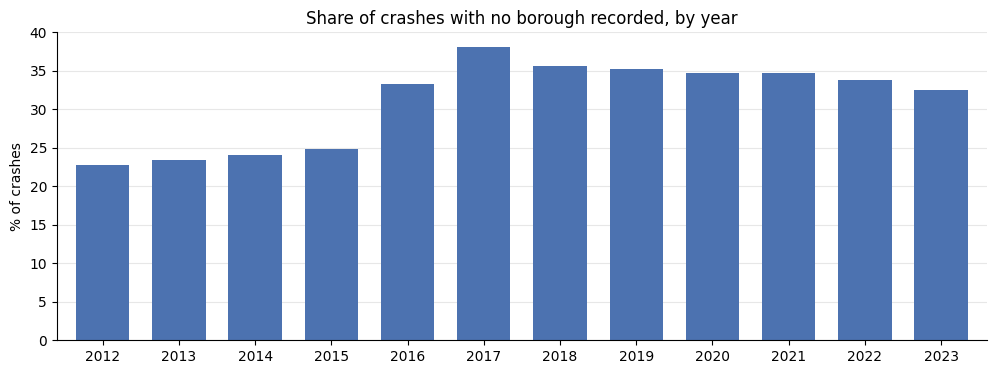

In [31]:
# Share of crashes with no borough, per year
borough_missing_by_year = (
    crashes["BOROUGH"].isna()
    .groupby(crashes["CRASH DATE"].dt.year)
    .mean()
    .mul(100)
    .round(1)
)
print(borough_missing_by_year)

ax = borough_missing_by_year.plot(kind="bar", color="#4C72B0", width=0.7)
ax.set_title("Share of crashes with no borough recorded, by year")
ax.set_xlabel("")
ax.set_ylabel("% of crashes")
ax.tick_params(axis="x", rotation=0)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.show()

Borough was missing for about 23–25% of crashes in 2012–2015, then jumped to 33% in 2016 and stayed between roughly 32% and 38% in every year after. A change this sudden, which then holds, points to a change in how crashes were recorded rather than in where they happened.

This means a borough-level series would show an artificial drop from 2016, because more crashes would fall into "unknown". We therefore forecast the city-wide total, which counts every crash regardless of whether its borough was recorded.

## Build and check the daily series

The forecasting target is the **number of crashes per day** across all of NYC. Each row is one crash, so we count rows per date.

### Count crashes per day

In [32]:
# Count rows per date
daily_crashes = crashes.groupby("CRASH DATE").size()

# Check for calendar days with no records at all
all_days = pd.date_range(daily_crashes.index.min(), daily_crashes.index.max(), freq="D")
print("Calendar days with no records:", len(all_days.difference(daily_crashes.index)))

# Make sure every calendar day appears once (a missing day would get 0)
daily_crashes = daily_crashes.reindex(all_days, fill_value=0).rename("crash_count")
daily_crashes.index.name = "date"

print("Days in series:", len(daily_crashes))
print("Total crashes:", f"{daily_crashes.sum():,}")

Calendar days with no records: 0
Days in series: 4066
Total crashes: 2,017,253


Every calendar day from 1 July 2012 to 18 August 2023 has at least one crash record, so no days had to be filled in. The series has **4,066 daily values**, and its total equals the number of rows after cleaning, so every crash is counted exactly once.

In [33]:
import os

for name in ["nyc_daily_crash_counts.csv", "nyc_weekly_crash_counts.csv"]:
    size_mb = os.path.getsize(name) / (1024 ** 2)
    print(name, round(size_mb, 2), "MB")

daily_saved = pd.read_csv("nyc_daily_crash_counts.csv")
weekly_saved = pd.read_csv("nyc_weekly_crash_counts.csv")
print("Daily CSV rows and total:", len(daily_saved), daily_saved["crash_count"].sum())
print("Weekly CSV rows and total:", len(weekly_saved), weekly_saved["crash_count"].sum())
print("Raw crash rows:", len(crashes))

nyc_daily_crash_counts.csv 0.06 MB
nyc_weekly_crash_counts.csv 0.01 MB
Daily CSV rows and total: 4062 2016512
Weekly CSV rows and total: 580 2015737
Raw crash rows: 2017253


count    4066.0
mean      496.1
std       168.8
min        94.0
25%       322.0
50%       531.0
75%       627.0
max      1160.0
Name: crash_count, dtype: float64

Average crashes per day by year:
date
2012    546.0
2013    558.0
2014    564.0
2015    595.0
2016    627.0
2017    632.0
2018    634.0
2019    579.0
2020    308.0
2021    303.0
2022    284.0
2023    260.0
Name: crash_count, dtype: float64


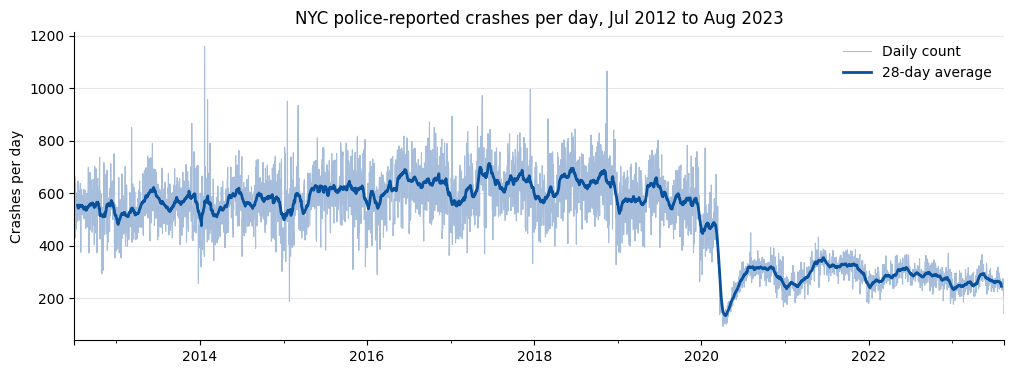

In [34]:
#Dispaly the daily series
print(daily_crashes.describe().round(1))
print("\nAverage crashes per day by year:")
print(daily_crashes.groupby(daily_crashes.index.year).mean().round(0))

ax = daily_crashes.plot(color="#A6BDDB", linewidth=0.8, label="Daily count")
daily_crashes.rolling(28, center=True).mean().plot(ax=ax, color="#08519C", linewidth=2, label="28-day average")
ax.set_title("NYC police-reported crashes per day, Jul 2012 to Aug 2023")
ax.set_xlabel("")
ax.set_ylabel("Crashes per day")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False)
plt.show()

**1. The series has two distinct levels, split by COVID-19.**
From 2012 to 2019, NYC averaged roughly 550–630 crashes a day, rising slightly to a peak in 2016–2018 (about 630 a day) before easing in 2019 (about 580). In March–April 2020 the count fell sharply, reaching the lowest values in the data (around 100 a day) during the lockdown. It partly recovered by mid-2020 but **never returned to the pre-COVID level**: 2021–2023 averaged about 260–300 crashes a day, roughly half the earlier level, and the level has continued to drift down slowly (about 303 in 2021, 285 in 2022, 260 in 2023).

**2. The overall mean is misleading.**
The mean of about 496 crashes a day falls between the two levels and describes neither period well. Statistics from the full series should be read with this in mind.

**3. Day-to-day variation shrank along with the level.**
Before 2020, daily counts typically ranged from about 400 to 800. After 2020 the range is closer to 200–400. Variation that grows and shrinks with the level suggests a log transformation, or percentage-based error metrics such as MAPE, may suit this series better than raw counts.

**4. There are isolated extreme days.**
A few days stand far above the surrounding values, the largest being about 1,160 crashes in early 2014 and about 1,060 in late 2018. There are also sharp single-day drops.

**5. A yearly pattern appears.**
The 28-day average tends to dip around the start of each year and rise in late spring and summer. This seasonality is examined further in EDA.

**6. The final days drop.**
The last values in August 2023 fall below the recent level. This may be a reporting delay rather than a real fall.

Note: 2012 (July–December) and 2023 (January–mid-August) are partial years, so their yearly averages cover only part of the seasonal cycle.

Crash reports can be entered days after the crash happened, so the final days of a data download may be under-counted. If they are, a model would treat a recording delay as a real drop in crashes. We compare the last two weeks with the typical daily level just before them.

In [35]:
# Typical level just before the end: median crashes per day in June–July 2023
baseline = daily_crashes["2023-06-01":"2023-07-31"].median()
print(f"Median crashes per day, June–July 2023: {baseline:.0f}")

# The last 14 days, with the weekday and each day as a % of that median
last_days = daily_crashes.tail(14).to_frame()
last_days["weekday"] = last_days.index.day_name()
last_days["pct_of_baseline"] = (last_days["crash_count"] / baseline * 100).round(0)

last_days

Median crashes per day, June–July 2023: 267


,crash_count,weekday,pct_of_baseline
date,,,
2023-08-05,249,Saturday,93.0
2023-08-06,252,Sunday,94.0
2023-08-07,241,Monday,90.0
2023-08-08,231,Tuesday,87.0
2023-08-09,241,Wednesday,90.0
2023-08-10,272,Thursday,102.0
2023-08-11,255,Friday,96.0
2023-08-12,275,Saturday,103.0
2023-08-13,243,Sunday,91.0


**Decision: end the series on 14 August 2023 and drop the last four days (15–18 August).**

From 5 to 14 August, daily counts stayed between 87% and 103% of the June–July median (267 crashes a day). The last four days then fall to 79%, 80%, 53% and 66%. Compared with the same weekday one week earlier, each of the four is clearly lower; for example, Thursday 17 August had 141 crashes against 272 the Thursday before. A run of low days at the very end of the data is the typical sign of a reporting delay: crashes that had happened but had not yet been entered when the data was downloaded.

The last two days are clearly incomplete. 15 and 16 August are less certain, but they are also dropped, for two reasons:
- Removing them costs only 2 of about 4,000 days.
- Keeping under-counted days is more harmful than it looks, because forecasts start from the most recent values. A naive baseline, for example, would forecast the next day as equal to the last observed day, so an incomplete final day would bias it directly.

Only the daily series is trimmed. The crash records themselves are kept unchanged.

In [36]:
#Trim the incomplete days
LAST_COMPLETE_DAY = "2023-08-14"

days_before = len(daily_crashes)
daily_crashes = daily_crashes[:LAST_COMPLETE_DAY]

print("Days removed:", days_before - len(daily_crashes))
print("Series now ends on:", daily_crashes.index.max().date(), daily_crashes.index.max().day_name())
print("Days in series:", len(daily_crashes))

Days removed: 4
Series now ends on: 2023-08-14 Monday
Days in series: 4062


### Outliers: real events or data errors?

Here we look for days that are far above or below the usual level and check whether any look like recording errors. Days caused by real events are kept, because they will happen again and the model should learn from them.

Because the level of the series halved in 2020, a single threshold for the whole series wouldn't work. It would flag almost every day after 2020 as "low". Instead, each day is compared with the **median of the 29 days around it**, so a day is only unusual relative to its own period.

In [37]:
# Local typical level: median of the 29 days centred on each day
local_median = daily_crashes.rolling(29, center=True, min_periods=15).median()
ratio = daily_crashes / local_median

# Flag days at least 50% above or 40% below their local level
is_outlier = (ratio > 1.5) | (ratio < 0.6)

outliers = pd.DataFrame({
    "crash_count": daily_crashes,
    "local_median": local_median.round(0),
    "ratio": ratio.round(2),
})[is_outlier]
outliers["weekday"] = outliers.index.day_name()

print("Days flagged:", len(outliers))
outliers

Days flagged: 26


,crash_count,local_median,ratio,weekday
date,,,,
2012-10-29,294,524.0,0.56,Monday
2012-11-03,307,524.0,0.59,Saturday
2013-03-08,850,535.0,1.59,Friday
2013-12-25,257,515.0,0.50,Wednesday
2014-01-21,1160,559.0,2.08,Tuesday
2014-02-03,957,515.0,1.86,Monday
2015-01-06,776,495.0,1.57,Tuesday
2015-01-09,750,495.0,1.52,Friday
2015-01-18,950,505.0,1.88,Sunday


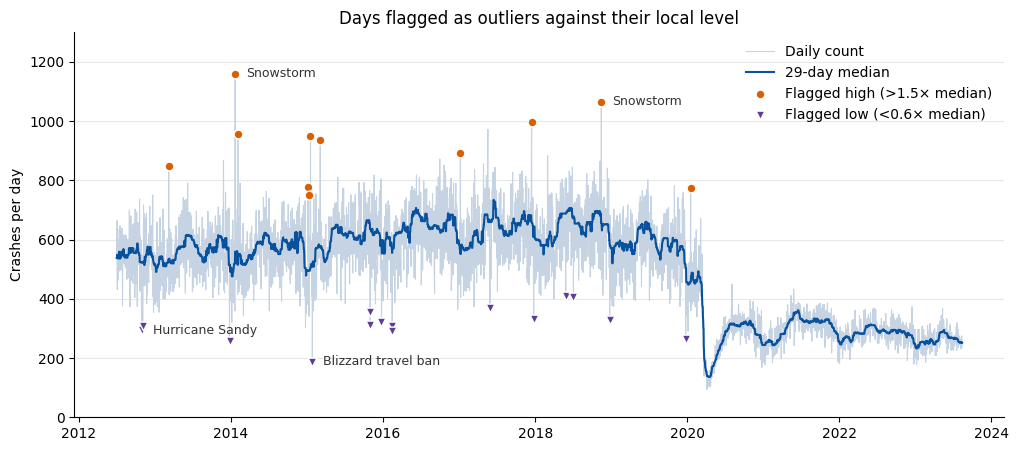

In [38]:
high = outliers[outliers["ratio"] > 1]
low = outliers[outliers["ratio"] < 1]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily_crashes.index, daily_crashes, color="#C6D3E3", linewidth=0.8, label="Daily count")
ax.plot(local_median.index, local_median, color="#08519C", linewidth=1.5, label="29-day median")
ax.scatter(high.index, high["crash_count"], color="#D95F02", s=40, zorder=3,
           edgecolor="white", linewidth=1, label="Flagged high (>1.5× median)")
ax.scatter(low.index, low["crash_count"], color="#5E3C99", s=40, marker="v", zorder=3,
           edgecolor="white", linewidth=1, label="Flagged low (<0.6× median)")

# Label a few of the best-known events
labels = {
    "2012-10-29": "Hurricane Sandy",
    "2014-01-21": "Snowstorm",
    "2015-01-27": "Blizzard travel ban",
    "2018-11-15": "Snowstorm",
}
for date, text in labels.items():
    ax.annotate(text, (pd.Timestamp(date), daily_crashes[date]), xytext=(8, 0),
                textcoords="offset points", ha="left", va="center", fontsize=9, color="#333333")

ax.set_ylim(0, 1300)
ax.set_title("Days flagged as outliers against their local level")
ax.set_ylabel("Crashes per day")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="upper right")
plt.show()

The chart shows the flagged days are isolated single-day events: each one is a sharp spike or dip that returns to the normal level the next day, rather than a run of unusual values that would suggest a recording problem. High days (orange) cluster in winter; low days (purple) fall on holidays and during major storms.

The COVID drop in 2020 is **not** flagged, because the 29-day median follows it down. This is intended: the check is designed for single unusual days, while the COVID shift is a lasting change in level, which is addressed in the EDA notebook. No day after January 2020 is flagged, which is also worth a closer look in EDA.

### Consistency checks on the crash records

These checks look for values that are impossible or that contradict each other within a row. They don't change the crash counts, but they show how reliable the other columns are, which matters if the group later uses injuries as an alternative target.

1. No count column should contain a negative number.
2. Persons injured should equal pedestrians + cyclists + motorists injured, and the same for killed.

In [39]:
# 1. Negative values in any of the eight count columns
count_cols = [col for col in crashes.columns if col.startswith("NUMBER OF")]
print("Negative values in any count column:", (crashes[count_cols] < 0).sum().sum())

# 2. Does the persons total equal the sum of the three groups?
injured_parts = crashes[["NUMBER OF PEDESTRIANS INJURED", "NUMBER OF CYCLIST INJURED",
                         "NUMBER OF MOTORIST INJURED"]].sum(axis=1)
killed_parts = crashes[["NUMBER OF PEDESTRIANS KILLED", "NUMBER OF CYCLIST KILLED",
                        "NUMBER OF MOTORIST KILLED"]].sum(axis=1)

# Only compare rows where the persons total is recorded
injured_mismatch = crashes["NUMBER OF PERSONS INJURED"].notna() & (crashes["NUMBER OF PERSONS INJURED"] != injured_parts)
killed_mismatch = crashes["NUMBER OF PERSONS KILLED"].notna() & (crashes["NUMBER OF PERSONS KILLED"] != killed_parts)
injured_higher = (crashes["NUMBER OF PERSONS INJURED"] > injured_parts).fillna(False)

print(f"\nInjured: total ≠ sum of groups in {injured_mismatch.sum():,} rows ({injured_mismatch.mean():.2%})")
print(f"  of which the total is higher: {injured_higher.sum():,}")
print(f"Killed: total ≠ sum of groups in {killed_mismatch.sum():,} rows")

print("\nInjury mismatches by year:")
print(injured_mismatch.groupby(crashes["CRASH DATE"].dt.year).sum())

Negative values in any count column: 0

Injured: total ≠ sum of groups in 6,445 rows (0.32%)
  of which the total is higher: 6,222
Killed: total ≠ sum of groups in 51 rows

Injury mismatches by year:
CRASH DATE
2012       6
2013       1
2014       8
2015       1
2016     472
2017     116
2018      82
2019       1
2020       0
2021    2041
2022    2288
2023    1429
dtype: int64


- **No negative counts**, so there are no impossible values in the injury and fatality columns.
- **The persons total doesn't match the three groups in 0.32% of rows (6,445).** In almost all of these (6,222), the total is *higher*, usually by one person. This means some injured people are counted in the total but not as a pedestrian, cyclist or motorist.
- **The mismatches cluster in time**: almost none before 2016, a jump in 2016, almost none in 2019–2020, and then 1,400–2,300 a year from 2021. A pattern like this suggests a change in how injured people were categorised (possibly road users who don't fit the three groups) rather than random errors.

**Decision: no changes.** The injury columns aren't used for the crash-count target, so the mismatch doesn't affect the forecast.

In [40]:
#Checking if Crash times are valid
crash_times = pd.to_datetime(crashes["CRASH TIME"], format="%H:%M", errors="coerce")

print("Invalid crash times:", crash_times.isna().sum())
print("Earliest:", crash_times.min().strftime("%H:%M"), "| Latest:", crash_times.max().strftime("%H:%M"))

Invalid crash times: 0
Earliest: 00:00 | Latest: 23:59


Every crash time is a valid time of day, running from 00:00 to 23:59, so there are no data-entry errors in this column. CRASH TIME stays as text because the forecast is daily and doesn't use the time of day.

## Weekly and monthly series

The daily series is the main target. Weekly and monthly totals are built as well, so the group can compare forecast horizons and levels of detail.

Only **complete** periods are kept. A week or month with missing days would have a lower total that looks like a real drop: for example, August 2023 has only 14 days of data after the trim in 5.3, so its total is less than half of July's.

In [41]:
# Weekly totals: weeks run Monday–Sunday and are labelled by their Sunday
weekly = daily_crashes.resample("W-SUN").agg(["sum", "count"])
print("Partial weeks dropped:")
print(weekly[weekly["count"] < 7])
weekly_crashes = weekly.loc[weekly["count"] == 7, "sum"].rename("crash_count")

# Monthly totals: labelled by the first day of the month
monthly = daily_crashes.resample("MS").agg(["sum", "count"])
print("\nPartial months dropped:")
print(monthly[monthly["count"] < monthly.index.days_in_month])
monthly_crashes = monthly.loc[monthly["count"] == monthly.index.days_in_month, "sum"].rename("crash_count")

print(f"\nComplete weeks: {len(weekly_crashes)} "
      f"({weekly_crashes.index.min().date()} to {weekly_crashes.index.max().date()})")
print(f"Complete months: {len(monthly_crashes)} "
      f"({monthly_crashes.index.min():%b %Y} to {monthly_crashes.index.max():%b %Y})")

Partial weeks dropped:
            sum  count
date                  
2012-07-01  538      1
2023-08-20  237      1

Partial months dropped:
             sum  count
date                   
2023-08-01  3533     14

Complete weeks: 580 (2012-07-08 to 2023-08-13)
Complete months: 133 (Jul 2012 to Jul 2023)


**What this shows**

- **Two partial weeks were dropped**, each with a single day of data: Sunday 1 July 2012 (the data starts on a Sunday) and Monday 14 August 2023 (the last day after the trim in 5.3). This leaves **580 complete weeks**, from the week ending 8 July 2012 to the week ending 13 August 2023.
- **One partial month was dropped**: August 2023, with 14 days and 3,533 crashes, compared with 8,147 in the full month of July. July 2012 is kept because the data starts on 1 July. This leaves **133 complete months**, July 2012 to July 2023.

**Implication for the horizon choice:** if the group trains only on data after the COVID drop, the monthly series would have only about 37 months, roughly three yearly cycles. That's very little for estimating yearly seasonality. The daily and weekly series give far more observations over the same period, which is a point in favour of forecasting at daily or weekly level.

## Save and verify the series

The three series are saved as CSV files for the EDA and modelling notebooks. Each file is then read back and compared with the series in memory, to confirm nothing changed in saving.

In [42]:
DAILY_FILE = "nyc_daily_crash_counts.csv"
WEEKLY_FILE = "nyc_weekly_crash_counts.csv"
MONTHLY_FILE = "nyc_monthly_crash_counts.csv"

saved_series = {DAILY_FILE: daily_crashes, WEEKLY_FILE: weekly_crashes, MONTHLY_FILE: monthly_crashes}

# Save each series
for file_name, series in saved_series.items():
    series.to_csv(file_name)

# Read each file back and compare it with the series in memory
for file_name, series in saved_series.items():
    saved = pd.read_csv(file_name, index_col=0, parse_dates=True)["crash_count"]
    identical = saved.index.equals(series.index) and (saved.values == series.values).all()
    print(f"{file_name}: {len(saved):,} rows, total {saved.sum():,} | identical to memory: {identical}")

nyc_daily_crash_counts.csv: 4,062 rows, total 2,016,512 | identical to memory: True
nyc_weekly_crash_counts.csv: 580 rows, total 2,015,737 | identical to memory: True
nyc_monthly_crash_counts.csv: 133 rows, total 2,012,979 | identical to memory: True


In [43]:
#Reconcile the daily total with the crash records
trimmed = crashes["CRASH DATE"] > LAST_COMPLETE_DAY

print(f"Crash rows after cleaning:           {len(crashes):,}")
print(f"Crashes on trimmed days (15–18 Aug): {trimmed.sum():,}")
print(f"Expected daily total:                {len(crashes) - trimmed.sum():,}")
print(f"Actual daily total:                  {daily_crashes.sum():,}")

Crash rows after cleaning:           2,017,253
Crashes on trimmed days (15–18 Aug): 741
Expected daily total:                2,016,512
Actual daily total:                  2,016,512


**What this shows**

All three files were saved correctly: reading them back gives exactly the same dates and counts as the series in memory.

The totals reconcile:
- **Daily:** the 2,017,253 crash rows after cleaning, minus the 741 crashes on the four trimmed days, gives exactly the daily total of 2,016,512. Every remaining crash is counted once.
- **Weekly** (2,015,737) is lower than daily by the 775 crashes in the two partial weeks dropped in Section 6 (538 + 237).
- **Monthly** (2,012,979) is lower than daily by the 3,533 crashes in the partial month of August 2023.

In [44]:
# Daily vs crash rows
trimmed = crashes["CRASH DATE"] > LAST_COMPLETE_DAY
print(f"Crash rows after cleaning:            {len(crashes):,}")
print(f"Crashes on trimmed days (15–18 Aug):  {trimmed.sum():,}")
print(f"Expected daily total:                 {len(crashes) - trimmed.sum():,}")
print(f"Actual daily total:                   {daily_crashes.sum():,}")

# Weekly vs daily
partial_weeks = weekly.loc[weekly["count"] < 7, "sum"].sum()
print(f"\nCrashes in dropped partial weeks:     {partial_weeks:,}")
print(f"Expected weekly total:                {daily_crashes.sum() - partial_weeks:,}")
print(f"Actual weekly total:                  {weekly_crashes.sum():,}")

# Monthly vs daily
partial_months = monthly.loc[monthly["count"] < monthly.index.days_in_month, "sum"].sum()
print(f"\nCrashes in dropped partial month:     {partial_months:,}")
print(f"Expected monthly total:               {daily_crashes.sum() - partial_months:,}")
print(f"Actual monthly total:                 {monthly_crashes.sum():,}")

Crash rows after cleaning:            2,017,253
Crashes on trimmed days (15–18 Aug):  741
Expected daily total:                 2,016,512
Actual daily total:                   2,016,512

Crashes in dropped partial weeks:     775
Expected weekly total:                2,015,737
Actual weekly total:                  2,015,737

Crashes in dropped partial month:     3,533
Expected monthly total:               2,012,979
Actual monthly total:                 2,012,979


**What this shows**

All three files were saved correctly: reading them back gives exactly the same dates and counts as the series in memory.

The totals reconcile:
- **Daily:** the 2,017,253 crash rows after cleaning, minus the 741 crashes on the four trimmed days, gives exactly the daily total of 2,016,512. Every remaining crash is counted once.
- **Weekly** (2,015,737) is lower than daily by the 775 crashes in the two partial weeks dropped some rows (538 + 237).
- **Monthly** (2,012,979) is lower than daily by the 3,533 crashes in the partial month of August 2023.

## Summary

### Cleaning decisions

| Check | Result | Action |
|---|---|---|
|Valid crash dates | All valid; 1 Jul 2012 to 18 Aug 2023 | None |
|Repeated collision IDs | None | None |
|Same crash entered twice under different IDs | 1,710 extra copies (0.08%), mostly with matching coordinates and consecutive IDs | **Removed**, keeping the first row of each group. 2,018,963 → 2,017,253 rows |
|Missing values | 20 of 29 columns have gaps; CRASH DATE is complete | Reported, not filled |
|Persons injured/killed stored as decimals | Caused by 18 and 31 missing values; all other values are whole numbers | **Converted** to nullable integer (Int64) |
|Contributing factor "Unspecified" | 34.3% of crashes | Kept as its own category |
|Coordinates equal to 0 | 4,235 rows | **Set to missing** (placeholder, not a location) |
|Borough missing by year | Jumps from about 25% to 33–38% from 2016 | Forecast the **city-wide total**, not boroughs |
|Calendar days with no records | None | None; 4,066 daily values |
|Reporting lag at the end | Last four days at 53–80% of normal | **Trimmed** 15–18 Aug 2023; series ends 14 Aug 2023 (4,062 days) |
|Outlier days | 26 days, all matching storms, holidays or winter weather | Kept unchanged (real events) |
|Negative counts; persons total vs. sum of groups | No negatives; total differs in 6,445 rows (0.32%), clustered in 2016 and 2021–2023 | No change; use the persons total if injuries are forecast |
|Valid crash times | All valid, 00:00 to 23:59 | None |
|Partial weeks and months | 2 partial weeks, 1 partial month | **Dropped**; 580 complete weeks, 133 complete months |
|Saved files match memory; totals reconcile | All three identical; every difference explained by the removals | None |

**Final outputs:** daily (4,062 days), weekly (580 weeks) and monthly (133 months) crash counts, saved to the `data/` folder of the group repository.

### Notes for the EDA and modelling notebooks

These came up during cleaning but are modelling questions rather than data errors:

1. **COVID level shift (5.2).** Daily crashes halved in spring 2020 and never recovered. The group needs to decide between training on post-2020 data only and keeping the full history with a COVID indicator.
2. **Variation shrinks with the level (5.2).** Daily counts ranged from about 400 to 800 before 2020 and from 200 to 400 after. A log transformation or percentage-based error metrics (e.g. MAPE) may suit the series better than raw counts.
3. **Seasonality (5.2).** The 28-day average dips around the start of each year. Yearly and day-of-week patterns should be measured in EDA.
4. **Holidays and weather (5.4).** The extreme days are storms and holidays. A public-holiday indicator could be built from the calendar; weather (e.g. snowfall) would need an external source.
5. **No flagged days after January 2020 (5.4).** Worth checking whether the post-COVID series reacts differently to storms and holidays.
6. **Forecast frequency (6).** After the COVID drop, the monthly series has only about 37 observations, which is little for yearly seasonality. Daily or weekly forecasting gives far more data.
7. **Alternative targets (4.4, 5.5).** Borough-level series would be distorted by the 2016 recording change. If injuries are forecast, the persons total should be used, not the sum of the three groups.

### 8.3 Limitations

- **Duplicates (3.3):** about 19% of the removed matches have no coordinates, so a small number may have been genuinely separate crashes. At 0.08% of rows, the effect on the series is negligible.
- **Reporting lag (5.3):** the cut-off at 14 August is a judgement. The last two days are clearly incomplete; 15–16 August were dropped as a precaution. The cut-off is set in one constant (`LAST_COMPLETE_DAY`) so it can easily be changed.
- **Outlier thresholds (5.4):** the 1.5× and 0.6× limits are a judgement. They were chosen to give a list short enough to check day by day; the decision to keep all flagged days doesn't depend on the exact thresholds.
- **Unexplained low days (5.4):** 31 October and 1 November 2015 have no clear cause. They were kept because their crashes are spread across all hours of the day, which doesn't look like lost records.
- **Recording changes:** the borough (4.4) and injury-category (5.5) patterns suggest the NYPD changed how crashes were recorded in 2016 and again around 2021. The total crash count looks unaffected, but this can't be fully confirmed from this dataset alone.